<a href="https://colab.research.google.com/github/milenachorzewska/useful_programs/blob/main/pages/solutions/02_sol_colab/colab_intro.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Colab Intro

##

## Sumowanie ciągu geometrycznego

Ciąg geometryczny jest ciągiem liczb, w którym każdy kolejny wyraz otrzymujemy przez pomnożenie poprzedniego wyrazu przez stałą liczbę nazywaną **ilorazem ciągu**.

Pierwsze $n$ wyrazów ciągu geometrycznego ma postać:

$
a_1,\quad a_1q,\quad a_1q^2,\quad \ldots,\quad a_1q^{n-1}
$

gdzie:

- $a_1$ oznacza pierwszy wyraz ciągu,
- $q$ oznacza iloraz ciągu,
- $n$ oznacza liczbę wyrazów.

Jeżeli $q \neq 1$, sumę pierwszych $n$ wyrazów ciągu geometrycznego obliczamy ze wzoru:

$$
S_n = a_1 \cdot \frac{1-q^n}{1-q}
$$

Jeżeli $q=1$, wszystkie wyrazy ciągu są takie same, dlatego:

$$
S_n = n \cdot a_1
$$

### Przykład

Dla:

- $a_1=2$,
- $q=3$,
- $n=4$,

otrzymujemy:

$$
S_4 = 2 + 6 + 18 + 54 = 80
$$

## Obliczanie $2+2$

In [9]:
wynik = 2 + 2

print("Wynik działania 2 + 2 =",wynik)

Wynik działania 2 + 2 = 4


## Obliczanie $\pi^\pi$

In [10]:
import math

wynik_pi = math.pi * math.pi

print("Wynik pi*pi = " ,wynik_pi)

Wynik pi*pi =  9.869604401089358


## Obliczanie $\sum_{n=1}^{100} x^2$

In [11]:
suma_kwadratow = sum(k**2 for k in range(1, 101))

print("Suma kwadratów liczb od 1 do 100 =", suma_kwadratow)

Suma kwadratów liczb od 1 do 100 = 338350


## Zapisywanie wyniku sumy

In [12]:
import os

suma_kwadratow = sum(k**2 for k in range(1, 101))

sciezka_pliku = "/content/colab_wynik.txt"

with open(sciezka_pliku, "w", encoding="utf-8") as plik:
    plik.write(
        f"Suma kwadratów liczb od 1 do 100 wynosi: {suma_kwadratow}\n"
    )

print("Plik został zapisany tutaj:")
print(sciezka_pliku)

Plik został zapisany tutaj:
/content/colab_wynik.txt


## Wykres $y=k^2$, gdzie $k=1, 2, 3,..., 20$

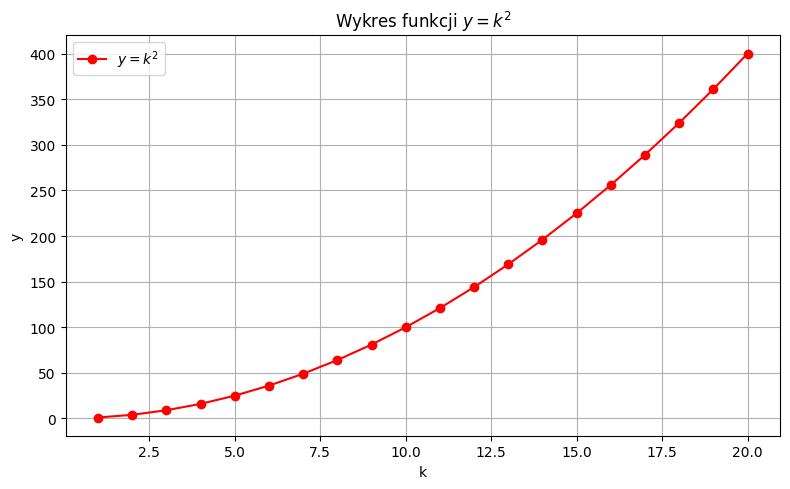

Wykres został zapisany tutaj:
/content/wykres.png
Czy plik istnieje? True


In [13]:
import os
import matplotlib.pyplot as plt

# Wartości k od 1 do 20
k = list(range(1, 21))

# Obliczenie y = k^2
y = [liczba**2 for liczba in k]

# Utworzenie wykresu
plt.figure(figsize=(8, 5))
plt.plot(k, y, marker="o", color="red", label=r"$y=k^2$")

plt.title(r"Wykres funkcji $y=k^2$")
plt.xlabel("k")
plt.ylabel("y")
plt.grid(True)
plt.legend()
plt.tight_layout()

# Zapis wykresu do pliku
sciezka_wykresu = "/content/wykres.png"
plt.savefig(sciezka_wykresu, dpi=300, bbox_inches="tight")

# Wyświetlenie wykresu
plt.show()

print("Wykres został zapisany tutaj:")
print(sciezka_wykresu)
print("Czy plik istnieje?", os.path.exists(sciezka_wykresu))

## Animacja wahadła

In [14]:
import os
import numpy as np
import matplotlib.pyplot as plt

from matplotlib.animation import FuncAnimation, FFMpegWriter
from IPython.display import Video, display

# Parametry fizyczne wahadła
g = 9.81
L = 1.0
kat_poczatkowy = np.radians(35)

# Parametry animacji
fps = 30
czas_trwania = 6
liczba_klatek = fps * czas_trwania

# Wartości czasu
t = np.linspace(0, czas_trwania, liczba_klatek)

# Przybliżony kąt wychylenia wahadła
theta = kat_poczatkowy * np.cos(np.sqrt(g / L) * t)

# Położenie ciężarka
x = L * np.sin(theta)
y = -L * np.cos(theta)

# Przygotowanie wykresu
fig, ax = plt.subplots(figsize=(6, 6))

ax.set_xlim(-1.3 * L, 1.3 * L)
ax.set_ylim(-1.3 * L, 0.3 * L)
ax.set_aspect("equal")

ax.set_title("Animacja wahadła")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.grid(True)

# Punkt zamocowania wahadła
ax.plot(0, 0, "ko", markersize=8)

# Elementy animacji
ramie, = ax.plot([], [], color="black", linewidth=2)
ciezarek, = ax.plot([], [], "o", color="blue", markersize=16)

napis_czas = ax.text(
    0.03,
    0.95,
    "",
    transform=ax.transAxes
)

def inicjalizacja():
    ramie.set_data([], [])
    ciezarek.set_data([], [])
    napis_czas.set_text("")

    return ramie, ciezarek, napis_czas

def aktualizacja(numer_klatki):
    aktualne_x = x[numer_klatki]
    aktualne_y = y[numer_klatki]

    ramie.set_data(
        [0, aktualne_x],
        [0, aktualne_y]
    )

    ciezarek.set_data(
        [aktualne_x],
        [aktualne_y]
    )

    napis_czas.set_text(
        f"Czas: {t[numer_klatki]:.2f} s"
    )

    return ramie, ciezarek, napis_czas

# Utworzenie animacji
animacja = FuncAnimation(
    fig,
    aktualizacja,
    frames=liczba_klatek,
    init_func=inicjalizacja,
    interval=1000 / fps,
    blit=True
)

# Ścieżka zapisu
sciezka_video = "/content/video.mp4"

# Ustawienia zapisu MP4
writer = FFMpegWriter(
    fps=fps,
    metadata={"title": "Animacja wahadła"},
    bitrate=1800
)

# Zapis filmu
animacja.save(
    sciezka_video,
    writer=writer
)

# Zamknięcie statycznego obrazu
plt.close(fig)

# Sprawdzenie pliku
print("Film został zapisany tutaj:")
print(sciezka_video)
print("Czy plik istnieje?", os.path.exists(sciezka_video))
print("Rozmiar pliku:", os.path.getsize(sciezka_video), "bajtów")

# Wyświetlenie filmu
display(Video(sciezka_video, embed=True))

Film został zapisany tutaj:
/content/video.mp4
Czy plik istnieje? True
Rozmiar pliku: 280027 bajtów


## Tworzenie z animacji pliku gif

In [15]:
import os
import subprocess

sciezka_mp4 = "/content/video.mp4"
sciezka_gif = "/content/video.gif"

# Sprawdzenie, czy istnieje film MP4
if not os.path.exists(sciezka_mp4):
    raise FileNotFoundError(
        "Nie znaleziono pliku video.mp4. "
        "Najpierw uruchom komórkę tworzącą animację wahadła."
    )

# Polecenie konwertujące MP4 do GIF
polecenie = [
    "ffmpeg",
    "-y",
    "-i",
    sciezka_mp4,
    "-vf",
    "fps=15,scale=480:-1:flags=lanczos",
    sciezka_gif
]

# Uruchomienie konwersji
wynik_konwersji = subprocess.run(
    polecenie,
    capture_output=True,
    text=True
)

# Sprawdzenie poprawności konwersji
if wynik_konwersji.returncode != 0:
    print(wynik_konwersji.stderr)
    raise RuntimeError(
        "Nie udało się utworzyć pliku GIF."
    )

print("GIF został zapisany w lokalizacji:")
print(sciezka_gif)
print("Czy plik istnieje?", os.path.exists(sciezka_gif))
print(
    "Rozmiar pliku:",
    os.path.getsize(sciezka_gif),
    "bajtów"
)

GIF został zapisany w lokalizacji:
/content/video.gif
Czy plik istnieje? True
Rozmiar pliku: 130750 bajtów


## Krzywa parametryczna

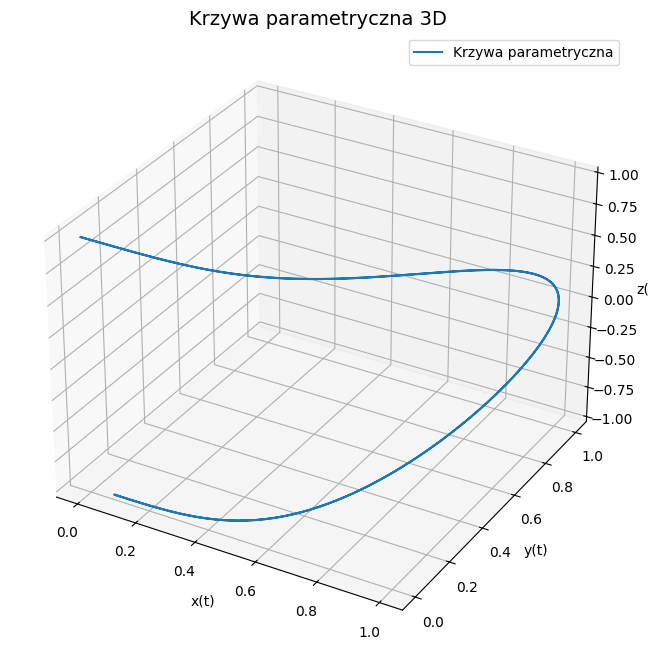

Wykres zapisano w:
/content/parametric_curve.png
Czy plik istnieje? True


In [16]:
import numpy as np
import matplotlib.pyplot as plt

# Wartości parametru t
t = np.linspace(0, 2 * np.pi, 500)

# Równania parametryczne
# Wartość bezwzględna zapobiega pierwiastkowaniu liczb ujemnych
x = np.sqrt(np.abs(np.sin(t)))
y = np.sin(t)**2
z = np.cos(t)

# Utworzenie wykresu 3D
fig = plt.figure(figsize=(8, 8))
ax = fig.add_subplot(111, projection="3d")

ax.plot(x, y, z, label="Krzywa parametryczna")

ax.set_title("Krzywa parametryczna 3D", fontsize=14)
ax.set_xlabel("x(t)")
ax.set_ylabel("y(t)")
ax.set_zlabel("z(t)")
ax.legend()

# Zapis wykresu
sciezka_pliku = "/content/parametric_curve.png"

plt.savefig(
    sciezka_pliku,
    dpi=300,
    bbox_inches="tight"
)

# Wyświetlenie wykresu
plt.show()

# Sprawdzenie zapisu
print("Wykres zapisano w:")
print(sciezka_pliku)
print("Czy plik istnieje?", os.path.exists(sciezka_pliku))